# Neural Networks for Image Processing - Concepts

**Business problem:** route a scanned handwritten digit to a processing queue, with human review for uncertain cases.
MNIST is a teaching benchmark, not evidence that a system can read complete invoices or bank documents.

In this notebook, we will:
1. Explain why local, shared filters are useful for images.
2. Trace convolution, ReLU, pooling and ten-class outputs.
3. Compare a CNN with a raw-pixel linear baseline without test leakage.
4. Interpret classification errors and limits of deployment evidence.

**SW07 Lecture 3. Prerequisites:** neural-network layers, gradient-based learning and validation from Lectures 1 and 2.
No advanced image processing is assumed. One worked filter example fits the lecture's 10-minute demonstration slot.
The complete [exercise](cnn_mnist_exercise.ipynb) is a separate practical; use the [solution](cnn_mnist_solution.ipynb) afterwards.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 7
np.random.seed(SEED)

## 1. Preserve the image's local structure

One observation is one 28 x 28 grayscale image. Its target is one of ten digits, 0 through 9.
A linear baseline flattens the image into 784 values and predicts ten scores.
It does not explicitly reuse a detector at different image positions.

A convolution slides one small set of learned weights across the image. The same filter can respond to a local pattern
in several positions. Weight sharing reduces parameters; it does not guarantee invariance to arbitrary transformations.
Real handwritten-document workflows also need segmentation, rotation handling and checks on unfamiliar inputs.

## 2. A worked filter, ReLU and pooling example

A filter response is the sum of pixel-by-weight products plus a bias. ReLU replaces negative responses by zero.
Max pooling keeps the largest activation in a local window. It reduces spatial resolution and can discard useful detail.

The fixed filter below is an illustration, not a trained recognizer. In the practical, backpropagation learns the filters.
Predict which side of a bright vertical stroke produces a positive response, then inspect the matrices.

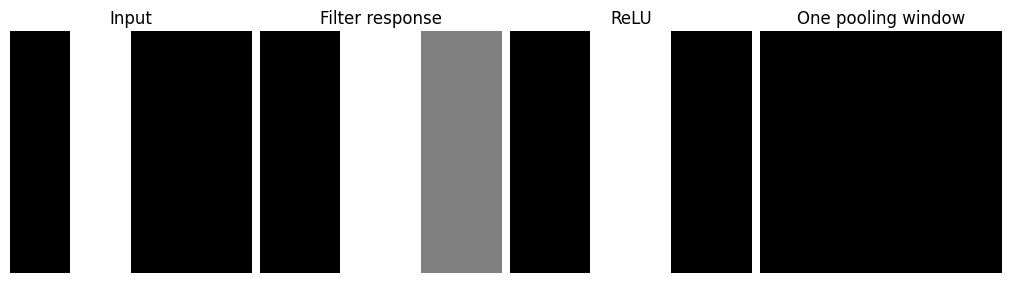

Filter responses:
 [[-2.  2.  0.]
 [-2.  2.  0.]
 [-2.  2.  0.]]
Pooled maximum: 2.0


In [2]:
image = np.array([[0, 1, 0, 0], [0, 1, 0, 0],
                  [0, 1, 0, 0], [0, 1, 0, 0]], dtype=float)
kernel = np.array([[1, -1], [1, -1]], dtype=float)
windows = np.lib.stride_tricks.sliding_window_view(image, kernel.shape)
response = (windows * kernel).sum(axis=(-2, -1))
activation = np.maximum(response, 0)
pooled = activation[:2, :2].max(keepdims=True)
figure, axes = plt.subplots(1, 4, figsize=(10, 3), layout='constrained')
for axis, values, title in zip(axes, [image, response, activation, pooled],
                                ['Input', 'Filter response', 'ReLU', 'One pooling window']):
    axis.imshow(values, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.show()
print('Filter responses:\n', response)
print('Pooled maximum:', pooled.item())

## 3. Follow the shapes and count the weights

The practical uses two valid 3 x 3 convolutions with 32 and 64 filters, two 2 x 2 pooling layers,
flattening, dropout at rate 0.5 and a ten-class softmax output.
Valid convolution uses no border padding; pooling uses stride 2 and drops incomplete windows.

For a convolution, parameter count is `(kernel height x kernel width x input channels + 1 bias) x filters`.
Flattening changes shape, not values. Pooling and dropout add no learned weights.
Dropout randomly masks activations during training, not during ordinary prediction.

In [3]:
layer_shapes = pd.DataFrame({
    'Layer': ['Input', 'Conv2D 32', 'MaxPool', 'Conv2D 64', 'MaxPool', 'Flatten', 'Dense 10'],
    'Output shape': ['28 x 28 x 1', '26 x 26 x 32', '13 x 13 x 32',
                     '11 x 11 x 64', '5 x 5 x 64', '1600', '10'],
    'Parameters': [0, (3 * 3 + 1) * 32, 0, (3 * 3 * 32 + 1) * 64,
                   0, 0, (1600 + 1) * 10],
})
display(layer_shapes)
print('CNN parameters:', int(layer_shapes['Parameters'].sum()))
print('Raw-pixel linear parameters:', (28 * 28 + 1) * 10)

,Layer,Output shape,Parameters
0,Input,28 x 28 x 1,0
1,Conv2D 32,26 x 26 x 32,320
2,MaxPool,13 x 13 x 32,0
3,Conv2D 64,11 x 11 x 64,18496
4,MaxPool,5 x 5 x 64,0
5,Flatten,1600,0
6,Dense 10,10,16010


CNN parameters: 34826
Raw-pixel linear parameters: 7850


## 4. Probabilities, evaluation and the review decision

Softmax turns ten scores into nonnegative values summing to one. Cross-entropy penalizes assigning low probability
to the true class. The most probable digit is a model prediction, not an automatic authorization to process a document.

Use the official 60,000-image training partition for a stratified 54,000/6,000 training/validation split.
Keep all 10,000 official test images outside model selection. Division by 255 is a fixed transformation, not a fitted scaler.
Train a raw-pixel linear softmax baseline and the CNN for the same five-epoch budget; choose by validation cross-entropy.
Also report a training-majority guessing baseline. Compare accuracy, log loss and per-digit errors.

A five-epoch budget does not equal equal compute. CNN training and deployment cost more operations.
Human-review workload, missed-digit costs and document-level accuracy need separate measurement.
Maximum softmax probability is not guaranteed to be calibrated confidence or a detector of unfamiliar images.

## Summary and knowledge check

- Shared filters preserve local structure; pooling trades resolution for compactness.
- Training, validation and final test evidence serve different purposes.
- A digit-level benchmark score is not business value or causal evidence.

1. What is shared when a filter moves across an image?
2. Why does a 3 x 3 valid convolution reduce 28 pixels to 26?
3. Why is the test set not suitable for choosing between the linear model and CNN?
4. What evidence is missing before high-scoring digits can bypass human review?

Try these before consulting the worked answers in the solution.

**Optional practical work:** compare a predeclared pooling or dropout change using training and validation only.
Plan new evaluation data before using historical test findings to redesign the system.

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023).
*An Introduction to Statistical Learning: With Applications in Python*. Springer. Neural-network material.
https://www.statlearning.com/

**Dataset:** LeCun, Y., Cortes, C., & Burges, C. J. C. *The MNIST Database of Handwritten Digits*.
https://yann.lecun.com/exdb/mnist/

**Official technical documentation:** [Keras MNIST](https://keras.io/api/datasets/mnist/),
[Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/),
[MaxPooling2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/),
[Dropout](https://keras.io/api/layers/regularization_layers/dropout/).

**Optional reading:** Zhang, A., Lipton, Z. C., Li, M., & Smola, A. J.
*Dive into Deep Learning*. Convolutional neural networks. https://d2l.ai/

**Environment:** [Pinned CNN requirements](../requirements-cnn-mnist.txt).
Practical notebooks require TensorFlow; the small calculations here use NumPy, pandas and matplotlib.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [4]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-25T20:17:33
